# Deep Learning NLP Text Classifier (PyTorch)
**Task 05 – RabTech Academy, AI & Machine Learning**  
**Author:** Mugesh L

**Problem:** SMS Spam Filter – classify a text message as *ham* (legitimate) or *spam*.

**Pipeline:** Tokenize & vectorize (TF-IDF) → Multi-layer neural network (Dropout + Batch Normalization + Early Stopping) → Train & validate with loss/accuracy curves → Test on unseen inputs with classification confidences.

In [1]:
%pip install torch scikit-learn pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
  Using cached torch-2.15.0-cp312-cp312-win_amd64.whl.metadata (36 kB)
  Using cached filelock-4.2.10-py3-none-any.whl.metadata (2.3 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.8/126.7 MB 6.7 MB/s eta 0:00:19
   ---------------------------------------- 1.6/126.7 MB 6.5 MB/s eta 0:00:20
    --------------------------------------- 1.8/126.7 MB 3.1 MB/s eta 0:00:40
    --------------------------------------- 2.9/126.7 MB 3.7 MB/s eta 0:00:34
   - -------------------------------------- 3.9/126.7 MB 4.0 MB/s eta 0:00:31


ERROR: Could not install packages due to an OSError: [Errno 2] No such file or directory: 'C:\\Users\\Dell\\AppData\\Local\\Packages\\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\\LocalCache\\local-packages\\Python312\\site-packages\\torch-2.15.0.dist-info\\licenses\\third_party\\cudnn_frontend\\python\\cudnn\\moe_ep\\_megamoe_backend\\cutedsl_src\\LICENSE.Apache-2.0'
HINT: This error might have occurred since this system does not have Windows Long Path support enabled. You can find information on how to enable this at https://pip.pypa.io/warnings/enable-long-paths


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\Dell\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import re, random, urllib.request, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| PyTorch:", torch.__version__)

Device: cpu | PyTorch: 2.15.0+cpu


## 1. Load the dataset
SMS Spam Collection (5,574 messages). If the download fails (no internet), a small built-in synthetic dataset is used so the notebook still runs end to end.

In [3]:
URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

def synthetic_dataset(n=1500):
    rng = random.Random(SEED)
    spam_t = ["WINNER! You have won a {p} prize. Call {n} now to claim",
              "Congratulations! Free {p} voucher, text WIN to {n} today",
              "URGENT! Your account is suspended. Click http://{n}.com to verify",
              "Get cheap loans approved instantly, reply YES to {n}",
              "You are selected for a free {p}. Claim now, offer ends today"]
    ham_t = ["Hey, are we meeting for {p} at {n} pm?",
             "Can you send me the notes for the {p} class",
             "I will reach home by {n}, keep dinner ready",
             "Thanks for the help yesterday, the {p} went well",
             "Don't forget to submit the {p} assignment tomorrow"]
    prizes = ["cash","iPhone","holiday","gift","lunch","project","lab","exam"]
    rows = []
    for _ in range(n):
        if rng.random() < 0.3:
            rows.append(("spam", rng.choice(spam_t).format(p=rng.choice(prizes), n=rng.randint(1000,99999))))
        else:
            rows.append(("ham", rng.choice(ham_t).format(p=rng.choice(prizes), n=rng.randint(1,11))))
    return pd.DataFrame(rows, columns=["label","text"])

try:
    raw = urllib.request.urlopen(URL, timeout=20).read().decode("utf-8")
    df = pd.read_csv(io.StringIO(raw), sep="\t", header=None, names=["label","text"])
    print("Loaded SMS Spam Collection from the web.")
except Exception as e:
    print("Download failed (", e, ") -> using synthetic fallback dataset.")
    df = synthetic_dataset()

df = df.dropna().drop_duplicates().reset_index(drop=True)
df["target"] = (df["label"] == "spam").astype(int)
print(df.shape)
df.head()

Loaded SMS Spam Collection from the web.
(5169, 3)


,label,text,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


label
ham     4516
spam     653
Name: count, dtype: int64


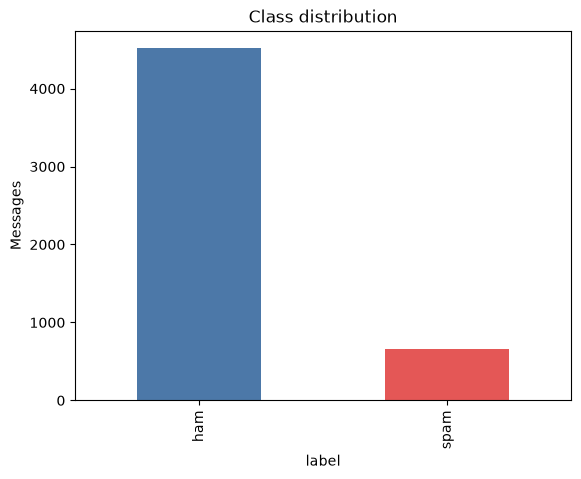

In [4]:
print(df["label"].value_counts())
df["label"].value_counts().plot(kind="bar", color=["#4c78a8","#e45756"], title="Class distribution")
plt.ylabel("Messages"); plt.show()

## 2. Tokenize & vectorize text (TF-IDF)
Text is lower-cased, cleaned, tokenized into unigrams + bigrams and converted to TF-IDF vectors. The vectorizer is **fit on the training split only** to avoid data leakage.

In [5]:
def clean(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\.\S+", " url ", t)
    t = re.sub(r"\d+", " num ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["text"].apply(clean)

X_train_txt, X_tmp_txt, y_train, y_tmp = train_test_split(
    df["clean"], df["target"], test_size=0.30, stratify=df["target"], random_state=SEED)
X_val_txt, X_test_txt, y_val, y_test = train_test_split(
    X_tmp_txt, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1,2), stop_words="english", sublinear_tf=True)
X_train = vectorizer.fit_transform(X_train_txt).toarray().astype("float32")
X_val   = vectorizer.transform(X_val_txt).toarray().astype("float32")
X_test  = vectorizer.transform(X_test_txt).toarray().astype("float32")

print("Train/Val/Test:", X_train.shape, X_val.shape, X_test.shape)
print("Sample vocabulary:", list(vectorizer.vocabulary_)[:12])

Train/Val/Test: (3618, 5000) (775, 5000) (776, 5000)
Sample vocabulary: ['think', 'going', 'come', 'think going', 'yeah', 'got', 'num', 'like', 'child', 'caught', 'till', 'won']


In [6]:
def loader(X, y, shuffle=False, bs=64):
    ds = TensorDataset(torch.tensor(X), torch.tensor(np.asarray(y), dtype=torch.long))
    return DataLoader(ds, batch_size=bs, shuffle=shuffle)

train_dl, val_dl, test_dl = loader(X_train, y_train, True), loader(X_val, y_val), loader(X_test, y_test)

# Class weights to handle imbalance (spam is the minority class)
counts = np.bincount(y_train)
class_w = torch.tensor(len(y_train) / (2.0 * counts), dtype=torch.float32).to(device)
print("Class weights:", class_w.cpu().numpy())

Class weights: [0.57228726 3.9584246 ]


## 3. Build the multi-layer neural network
Architecture: `Input(5000) → [Linear → BatchNorm → ReLU → Dropout] × 3 → Linear(2)`

In [7]:
class TextClassifier(nn.Module):
    def __init__(self, in_dim, hidden=(256, 128, 64), p=0.4, n_classes=2):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p)]
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

model = TextClassifier(X_train.shape[1]).to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

criterion = nn.CrossEntropyLoss(weight=class_w)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

TextClassifier(
  (net): Sequential(
    (0): Linear(in_features=5000, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.4, inplace=False)
    (12): Linear(in_features=64, out_features=2, bias=True)
  )
)
Trainable parameters: 1322434


## 4. Train & validate with Early Stopping
Training stops when validation loss has not improved for `patience` epochs; the best weights are restored.

In [8]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=1e-4):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.counter, self.best_state, self.stop = float("inf"), 0, None, False
    def __call__(self, val_loss, model):
        if val_loss < self.best - self.min_delta:
            self.best, self.counter = val_loss, 0
            self.best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience: self.stop = True

def run_epoch(dl, train=False):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb); loss = criterion(out, yb)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
early = EarlyStopping(patience=5)
MAX_EPOCHS = 50

for epoch in range(1, MAX_EPOCHS + 1):
    tl, ta = run_epoch(train_dl, True)
    vl, va = run_epoch(val_dl, False)
    scheduler.step(vl)
    for k, v in zip(history, (tl, vl, ta, va)): history[k].append(v)
    print(f"Epoch {epoch:02d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
    early(vl, model)
    if early.stop:
        print(f"Early stopping triggered at epoch {epoch}. Best val loss: {early.best:.4f}")
        break

model.load_state_dict(early.best_state)

Epoch 01 | train loss 0.3732 acc 0.8123 | val loss 0.3828 acc 0.9677
Epoch 02 | train loss 0.1172 acc 0.9795 | val loss 0.1114 acc 0.9652
Epoch 03 | train loss 0.0542 acc 0.9920 | val loss 0.0895 acc 0.9781
Epoch 04 | train loss 0.0383 acc 0.9923 | val loss 0.0812 acc 0.9794
Epoch 05 | train loss 0.0253 acc 0.9950 | val loss 0.0986 acc 0.9806
Epoch 06 | train loss 0.0206 acc 0.9953 | val loss 0.1039 acc 0.9781
Epoch 07 | train loss 0.0186 acc 0.9970 | val loss 0.1163 acc 0.9845
Epoch 08 | train loss 0.0148 acc 0.9975 | val loss 0.1692 acc 0.9871
Epoch 09 | train loss 0.0084 acc 0.9983 | val loss 0.1159 acc 0.9806
Early stopping triggered at epoch 9. Best val loss: 0.0812


<All keys matched successfully>

## 5. Loss & accuracy convergence curves

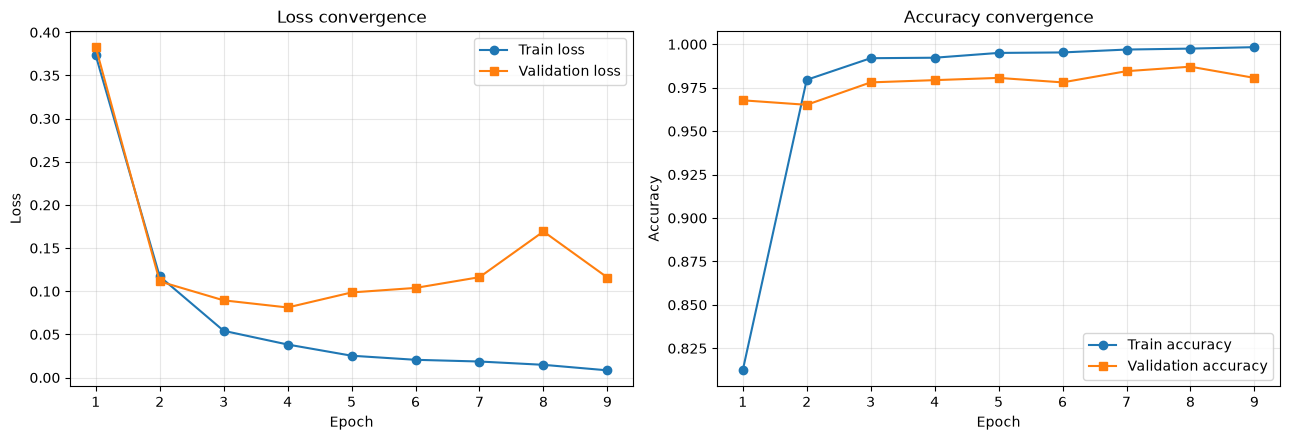

In [9]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(epochs, history["train_loss"], "o-", label="Train loss")
ax[0].plot(epochs, history["val_loss"], "s-", label="Validation loss")
ax[0].set_title("Loss convergence"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(epochs, history["train_acc"], "o-", label="Train accuracy")
ax[1].plot(epochs, history["val_acc"], "s-", label="Validation accuracy")
ax[1].set_title("Accuracy convergence"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)

plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

## 6. Evaluate on the held-out test set

              precision    recall  f1-score   support

         ham     0.9956    0.9926    0.9941       678
        spam     0.9500    0.9694    0.9596        98

    accuracy                         0.9897       776
   macro avg     0.9728    0.9810    0.9768       776
weighted avg     0.9898    0.9897    0.9897       776



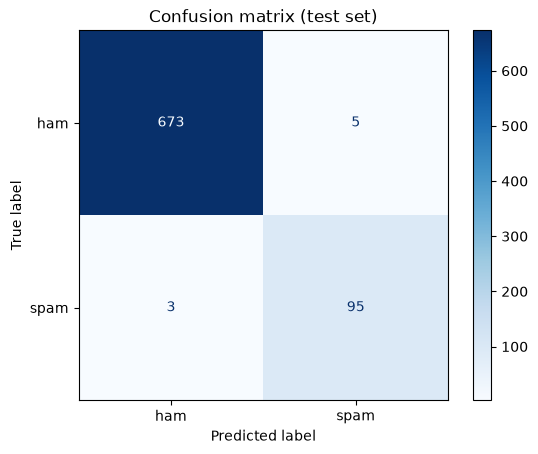

In [10]:
model.eval()
with torch.no_grad():
    logits = model(torch.tensor(X_test).to(device))
    y_pred = logits.argmax(1).cpu().numpy()

print(classification_report(y_test, y_pred, target_names=["ham", "spam"], digits=4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["ham", "spam"]).plot(cmap="Blues")
plt.title("Confusion matrix (test set)"); plt.show()

## 7. Test on unseen sample inputs (classification confidences)

In [11]:
def predict(messages):
    model.eval()
    X = vectorizer.transform([clean(m) for m in messages]).toarray().astype("float32")
    with torch.no_grad():
        probs = torch.softmax(model(torch.tensor(X).to(device)), dim=1).cpu().numpy()
    return pd.DataFrame({
        "message": messages,
        "prediction": ["SPAM" if p[1] > 0.5 else "HAM" for p in probs],
        "P(ham)": probs[:, 0].round(4),
        "P(spam)": probs[:, 1].round(4),
        "confidence": probs.max(1).round(4),
    })

samples = [
    "Congratulations! You have won a free iPhone. Call 09061234567 now to claim your prize!",
    "URGENT: your bank account is suspended. Click http://secure-verify.com to restore access",
    "Free entry in a weekly competition! Text WIN to 80086 to receive a cash reward",
    "Hey, are we still meeting at the library after class today?",
    "Please send me the DBMS lab record before tomorrow morning",
    "Amma said dinner is ready, come home soon",
    "Get cheap personal loans approved instantly, reply YES now",
    "Can you share the notes for the operating systems unit 3?",
]
pd.set_option("display.max_colwidth", 90)
results = predict(samples)
results

,message,prediction,P(ham),P(spam),confidence
0,Congratulations! You have won a free iPhone. Call 09061234567 now to claim your prize!,SPAM,0.0026,0.9974,0.9974
1,URGENT: your bank account is suspended. Click http://secure-verify.com to restore access,SPAM,0.0043,0.9957,0.9957
2,Free entry in a weekly competition! Text WIN to 80086 to receive a cash reward,SPAM,0.0017,0.9983,0.9983
3,"Hey, are we still meeting at the library after class today?",HAM,0.9895,0.0105,0.9895
4,Please send me the DBMS lab record before tomorrow morning,HAM,0.9795,0.0205,0.9795
5,"Amma said dinner is ready, come home soon",HAM,0.9847,0.0153,0.9847
6,"Get cheap personal loans approved instantly, reply YES now",SPAM,0.0367,0.9633,0.9633
7,Can you share the notes for the operating systems unit 3?,HAM,0.9865,0.0135,0.9865


## 8. Conclusion
- Messages were vectorized with **TF-IDF** (unigrams + bigrams, 5,000 features), fit on the training split only.
- A **multi-layer neural network** (256-128-64) with **Batch Normalization**, **Dropout (0.4)** and **early stopping** was trained in PyTorch, using class weights for the imbalanced spam class.
- Training/validation **loss and accuracy curves** show convergence; the best-validation-loss weights were restored.
- The model was evaluated on a held-out test set and on unseen sample messages, with **softmax confidence scores** for each prediction.

**Possible improvements:** Hugging Face transformer embeddings (e.g. DistilBERT), hyperparameter tuning, k-fold cross-validation.